In [26]:
import torch

урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-svertochnye-neyronnye-seti-vgg-16-i-vgg-19  
PyTorch: https://pytorch.org/tutorials/  
VGG: https://pytorch.org/vision/master/models/vgg.html  

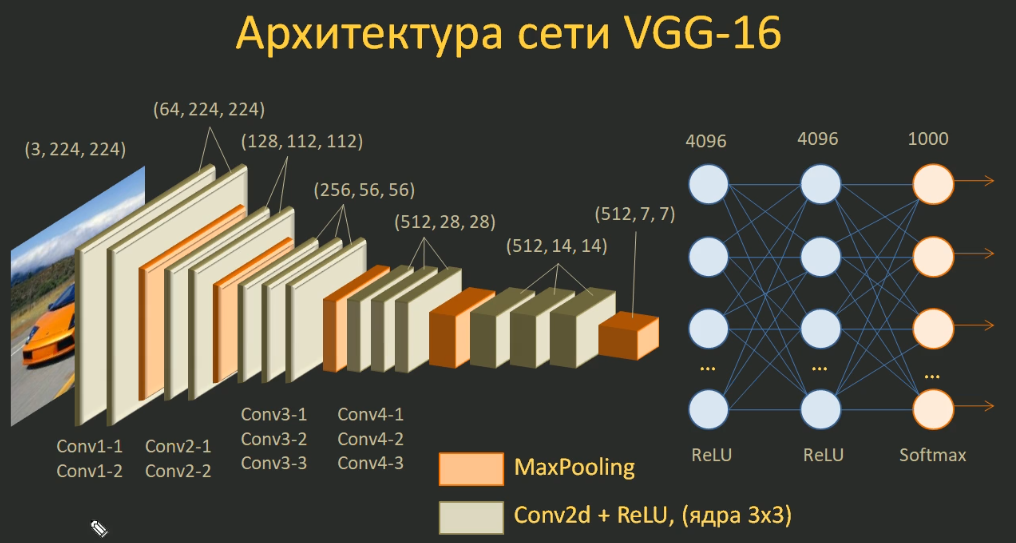

Два подряд сверточных слоя с ядром (3, 3) эквивалентны одному слою с ядром (5, 5). Но так мы получаем несколько меньше весов при той же области охвата

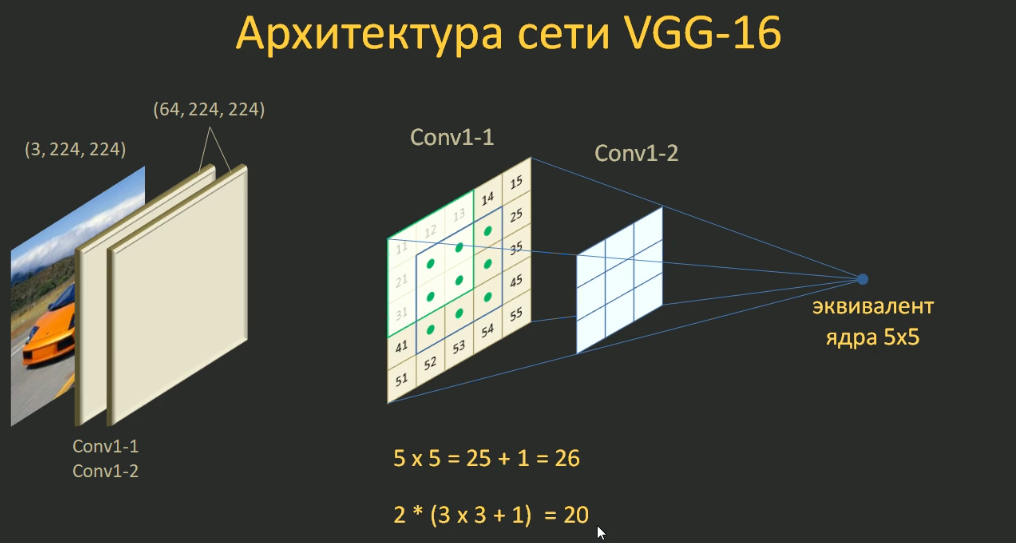

список моделей (предобученных или нет) находится здесь  
https://docs.pytorch.org/vision/master/models/vgg.html

In [1]:
from torchvision import models

In [4]:
# модель со случайными весами

model = models.vgg16()
model

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [6]:
# модель с предобученными весами
weights = models.VGG16_Weights.DEFAULT

VGG16_Weights.IMAGENET1K_V1

Веса - это отдельный класс с некоторыми параметрами. у него есть свои атрибуты

In [7]:
dir(weights)

['__class__',
 '__doc__',
 '__eq__',
 '__hash__',
 '__module__',
 'get_state_dict',
 'meta',
 'name',
 'transforms',
 'url',
 'value',
 'verify']

In [11]:
weights.meta['categories']

['tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen',
 'ostrich',
 'brambling',
 'goldfinch',
 'house finch',
 'junco',
 'indigo bunting',
 'robin',
 'bulbul',
 'jay',
 'magpie',
 'chickadee',
 'water ouzel',
 'kite',
 'bald eagle',
 'vulture',
 'great grey owl',
 'European fire salamander',
 'common newt',
 'eft',
 'spotted salamander',
 'axolotl',
 'bullfrog',
 'tree frog',
 'tailed frog',
 'loggerhead',
 'leatherback turtle',
 'mud turtle',
 'terrapin',
 'box turtle',
 'banded gecko',
 'common iguana',
 'American chameleon',
 'whiptail',
 'agama',
 'frilled lizard',
 'alligator lizard',
 'Gila monster',
 'green lizard',
 'African chameleon',
 'Komodo dragon',
 'African crocodile',
 'American alligator',
 'triceratops',
 'thunder snake',
 'ringneck snake',
 'hognose snake',
 'green snake',
 'king snake',
 'garter snake',
 'water snake',
 'vine snake',
 'night snake',
 'boa constrictor',
 'rock python',
 'Indian cobr

In [13]:
weights.transforms()

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

Итак, объявим предобученную модель и подадим ей на вход какое-нибудь фото

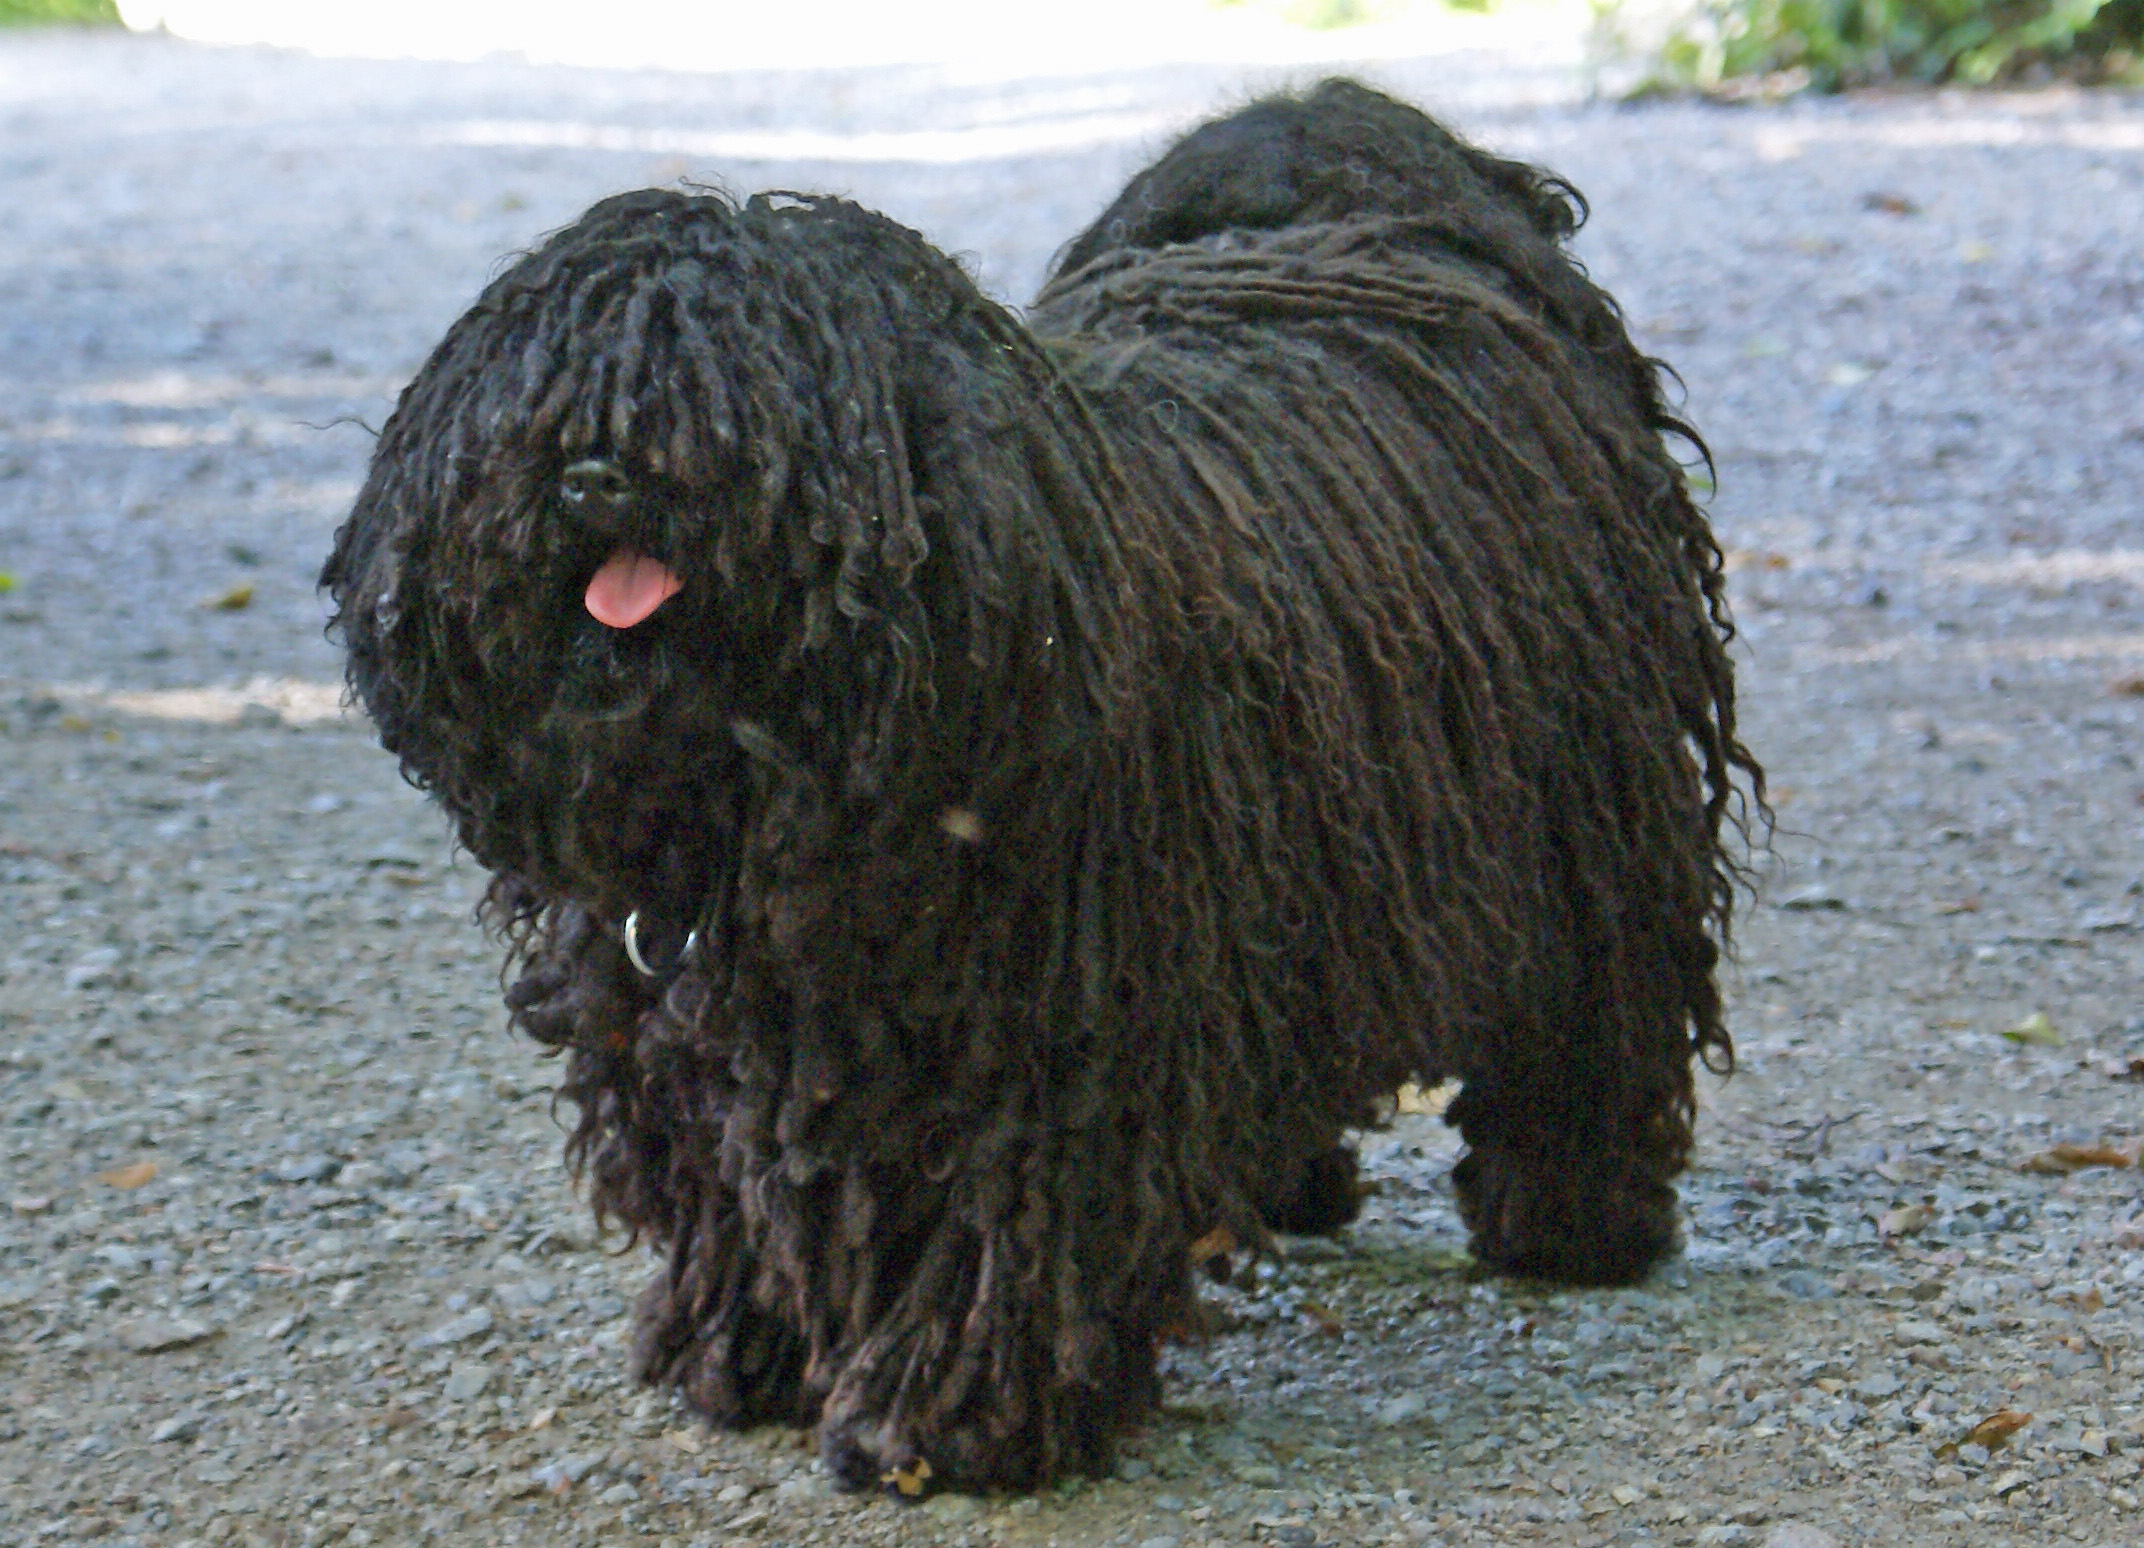

In [68]:
from PIL import Image

img =Image.open('puli.jpg').convert('RGB')
img

In [41]:
weights = models.VGG16_Weights.DEFAULT
transforms = weights.transforms()
img_tr = transforms(img).unsqueeze(0)
img_tr.shape


torch.Size([1, 3, 224, 224])

In [42]:
model = models.vgg16(weights=weights)

model.eval()
logits = model(img_tr).squeeze(0)ты где
pred = logits.softmax(dim=0)
print(f'predicted class is "{weights.meta["categories"][torch.argmax(pred).item()]}"')

predicted class is "komondor"


In [57]:
res = logits.softmax(dim=0).sort(descending=True)
for s, i in zip(res[0][:10], res[1][:10]):
    print(f'{weights.meta["categories"][i]}: {s:.4f}')

komondor: 0.9794
briard: 0.0087
Tibetan terrier: 0.0078
Irish water spaniel: 0.0010
swab: 0.0010
Bouvier des Flandres: 0.0005
standard poodle: 0.0003
Newfoundland: 0.0002
miniature poodle: 0.0001
cocker spaniel: 0.0001


В модели можно обращаться только к сверточным или только к полносвязным слоям

In [59]:
model.features

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [60]:
model.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

Поскольку эти половинки реализованы скорее всего через nn.Sequential, то можно обращаться к ним отдельно

In [63]:
convoluted = model.features(img_tr)
convoluted.shape

torch.Size([1, 512, 7, 7])

In [65]:
classified = model.classifier(convoluted.flatten())
classified.shape

torch.Size([1000])